# PyMOL-Copilot: Sichere PyMOL-Befehle mit einem lokalen Sprachmodell

**Autoren:** Martin Urban und Hannah Kullik

Inhalt:

1. **Problem**: PyMOL-Befehle aus **natürlicher Sprache** erzeugen
2. Eine **eingeschränkte Befehlssprache** als Sicherheitsnetz
3. **Datensatz**: per Programm erzeugt und von einem **Orakel** geprüft
4. **Fine-Tuning** eines kleinen Sprachmodells (Llama-3.2-1B) mit **LoRA**
5. **Evaluation**: Basismodell gegen feinabgestimmtes Modell
6. **Anwendung**: der Copilot in PyMOL
7. **Grenzen** und Ausblick

<img src="../assets/splash_screen.png" width="500px">

- Kurzfassung des ausführlichen (englischen) Notebooks `pymol_copilot.ipynb`
- Notebook ist *ausgeführt* gespeichert: lesbar, ohne etwas zu starten
- Rechenintensive Schritte (Datensatz erzeugen, Training, Evaluation) laufen hier **nicht**
    - stattdessen: Laden der im Repository abgelegten Ergebnisse
- Schnelle Schritte (Millisekunden) laufen live
- Die Live-Vorführung des Copiloten (Abschnitt 6) braucht einen Lemonade-Server mit dem Modell
    - eingeschaltet mit der Umgebungsvariable `PMC_NOTEBOOK_DEMO=1`
    - im Windows-Bundle automatisch: es startet seinen eigenen Server auf der CPU

In [1]:
# Copyright 2026 PyMOL Copilot contributors.
"""Kernel vorbereiten: die Pakete des Repositorys einbinden."""

import importlib
import os
import sys
import warnings
from pathlib import Path

# Fortschrittsbalken des Tokenizers bräuchten ipywidgets
warnings.filterwarnings("ignore", message="IProgress not found")

# Hilfsfunktionen liegen neben dem Notebook im Ordner notebooks/
sys.path.insert(0, str(Path.cwd()))
support = importlib.import_module("notebook_support")

# Pakete des Repositorys (src/) importierbar machen
support.setup_paths()

# Live-Vorführung in Abschnitt 6: nur mit Lemonade-Server und dem Modell
RUN_DEMO = os.environ.get("PMC_NOTEBOOK_DEMO") == "1"

# PyMOL schon jetzt starten, bevor Tokenizer und LangGraph geladen sind:
# unter Windows startet PyMOL danach im Jupyter-Kernel nicht mehr
if RUN_DEMO:
    cmd = support.launch_pymol()

## 1 Problemstellung

- **PyMOL**: Molekülviewer für Proteinstrukturen, gesteuert über eine eigene Befehlssprache
- Beispiele:
    - `color red, chain A` färbt alle Atome von Kette A rot
    - `show sticks, resn ZN` zeigt die Zink-Ionen als Stäbchen
- Befehle schreiben erfordert Kenntnis der **Selektionssyntax**
- Idee: Nutzer:in beschreibt den Wunsch in natürlicher Sprache, ein **LLM** schreibt die Befehle
- Problem: ein allgemeines Chat-LLM ist hier **unsicher**
    - die PyMOL-Sprache kann auch Python ausführen, Dateien laden und Plugins aufrufen
- Ziel: ein **kleines, lokales** Modell, nichts verlässt den Rechner
- Ausgabe des Modells: ein **Plan**, d.h. eine kurze Liste von PyMOL-Befehlen

### 1.1 Ablauf einer Anfrage
1. **Snapshot**: die laufende PyMOL-Sitzung wird ausgelesen
2. **Strukturkarte**: der Snapshot als Text (Objekt, Atome, Farben, Darstellungen)
3. **Generierung**: das lokale LLM erhält Karte und Wunsch und schreibt den Plan
4. **Validierung**: der Plan wird
    - geparst,
    - von einer unabhängigen Policy geprüft und
    - in einem *separaten* PyMOL-Prozess probeweise ausgeführt
    - bei einem Fehler: höchstens zwei Reparaturversuche
5. **Freigabe**: Nutzer:in sieht die Befehle und die getroffenen Atome und bestätigt mit `copilot_apply`
6. **Anwenden**: die Sitzung wird vorher gesichert und bei einem Fehler wiederhergestellt

- der *einzige gelernte* Teil ist das **Sprachmodell** in Schritt 3

## 2 Eine eingeschränkte Befehlssprache

- nur **fünf Verben**: `select`, `color`, `show`, `hide`, `orient`
- Selektionen aus **sechs Termen**: `chain`, `resi`, `resn`, `name`, `hetatm`, `polymer`
- verknüpft mit `and`, `or` und `not`
- alles andere wird **vor** der Ausführung abgelehnt
- eigener Parser (`pmc_core.parser`): ungeprüfter Text wird *nie* an den Parser von PyMOL gegeben

In [2]:
from pmc_core.parser import ParseRejection
from pmc_core.parser import parse_pml
from pmc_core.policy import evaluate_plan

beispiele = [
    "color red, chain A",
    "hide lines, chain B and not hetatm",
    "load /etc/passwd",
    "set sphere_scale, 2",
    "Color red, chain A",
]
for text in beispiele:
    ergebnis = parse_pml(text + "\n")
    if isinstance(ergebnis, ParseRejection):
        print(f"abgelehnt  {text!r:40} Grund: {ergebnis.category}")
    else:
        erlaubt = evaluate_plan(ergebnis).allowed
        print(f"geparst    {text!r:40} Policy erlaubt: {erlaubt}")

geparst    'color red, chain A'                     Policy erlaubt: True
geparst    'hide lines, chain B and not hetatm'     Policy erlaubt: True
abgelehnt  'load /etc/passwd'                       Grund: unknown_verb
abgelehnt  'set sphere_scale, 2'                    Grund: unknown_verb
abgelehnt  'Color red, chain A'                     Grund: unknown_verb


- Beachte: der Parser **normalisiert nichts**, z.B. keine Groß-/Kleinschreibung (`Color`)
    - beim Normalisieren beginnt ein Parser, Text zu akzeptieren, an den niemand gedacht hat

## 3 Datensatz

- Ein Modell lernt aus Beispielen: (Struktur, Wunsch, korrekter Plan)
- Solche Beispiele von Nutzer:innen gibt es nicht
- Von Hand oder von einem anderen LLM geschriebene Pläne können **falsch** sein
- Daher wird jedes Beispiel **per Programm** erzeugt ("program-first"):
    - der Plan wird per Code aufgezählt
    - ein **Orakel** sagt sein Ergebnis voraus, *ohne* PyMOL
    - der Plan wird in echtem PyMOL ausgeführt
    - das Beispiel bleibt nur, wenn PyMOLs Ergebnis **exakt** der Vorhersage entspricht

### 3.1 Synthetische Strukturen und Strukturkarte
- 24 kleine, **synthetische** Proteine
    - mehrere Ketten, Hetero-Atome (Zink, Wasser), mehrere Zustände, alternative Positionen, Insertion Codes
- synthetisch mit Absicht: keine PDB-Daten, jedes Atom ist bekannt
- das Modell sieht eine Struktur als **Strukturkarte** (Text), z.B.:

In [3]:
from pmc_core.card import render_for_runtime
from pmc_data.structures import StructureSpec
from pmc_data.structures import build_structure

# Ein Wunsch aus dem handgeprüften Gold-Set und seine Struktur
gold = support.load_jsonl("src/pmc_data/gold/gold_samples.jsonl")
beispiel = next(row for row in gold if row["sample_id"] == "gold_056")
spec = StructureSpec.from_dict(beispiel["structure"]["spec"])
snapshot = build_structure(spec)

anzahl_atome = sum(len(state.atoms) for state in snapshot.states)
print(f"Struktur '{spec.spec_id}' mit {anzahl_atome} Atomen")
print("Wunsch:", beispiel["intent"])
print()
karte = render_for_runtime(snapshot)
print("\n".join(karte.splitlines()[:10]))
print("...")

Struktur 'two_chains_hetatm' mit 36 Atomen
Wunsch: select the zinc ions, make them silver and show them as dots

card-version=1
status=complete
unsupported state=measurement-objects route=plan-report
unsupported state=explicit-polymer-classification route=contract-freeze
object name="pmc_structure" enabled=true states=1
state index=1 atoms=36 emitted=36 truncated=false
atom state=1 serial=3 name="C" alt="" resn="ALA" chain="A" resv=1 ins="" elem="C" hetatm=false occupancy=1 b_factor=20 color=3 reps="lines" label=null coord="-7.5,16,21"
atom state=1 serial=2 name="CA" alt="" resn="ALA" chain="A" resv=1 ins="" elem="C" hetatm=false occupancy=1 b_factor=20 color=3 reps="lines" label=null coord="0.5,-19,-28"
atom state=1 serial=1 name="N" alt="" resn="ALA" chain="A" resv=1 ins="" elem="N" hetatm=false occupancy=1 b_factor=20 color=3 reps="lines" label=null coord="-25.5,-29,-16.5"
atom state=1 serial=4 name="O" alt="" resn="ALA" chain="A" resv=1 ins="" elem="O" hetatm=false occupancy=1 b_fa

### 3.2 Pläne aufzählen
- `enumerate_plans` erzeugt je Struktur Pläne über alle Verben, Terme und Ausdrucksformen
- jeder Plan erhält einen Wunsch aus einer **Satzvorlage**

In [4]:
from pmc_data.taxonomy import enumerate_plans

kandidaten = enumerate_plans(snapshot, seed=20260921)
plan = next(c for c in kandidaten if c.category.startswith("color+select"))

print(f"{len(kandidaten)} Kandidaten-Pläne für diese Struktur, z.B.:")
print("Wunsch:   ", plan.intent)
print("Kategorie:", plan.category)
print(plan.plan.render_pml(), end="")

567 Kandidaten-Pläne für diese Struktur, z.B.:
Wunsch:    Select chain A and color it neptunium.
Kategorie: color+select/chain/single
select copilot_sel0001, chain A
color neptunium, copilot_sel0001


### 3.3 Das Orakel
- sagt ohne PyMOL voraus:
    - den Zustand nach dem Plan
    - wie viele Atome jede Selektion trifft
- lieber **ablehnen als raten**: was nicht vorhersagbar ist, wird benannt

In [5]:
from pmc_data.oracle import apply_plan

vorhersage = apply_plan(snapshot, plan.plan)
print("Atome je Selektion:  ", vorhersage.selection_counts)
print("Zustand vorhergesagt:", vorhersage.snapshot is not None)
print("Nicht geprüft:       ", vorhersage.unsupported or "nichts")

Atome je Selektion:   (('copilot_sel0001', 18),)
Zustand vorhergesagt: True
Nicht geprüft:        nichts


- jeder Versuch beim Erzeugen des Datensatzes ist damit ein **Differenztest**: Orakel gegen PyMOL
- Ergebnis für 4.000 Versuche:

In [6]:
bericht = support.load_json("docs/dataset/linux-regeneration/report.json")
gruende: dict[str, int] = {}
for kategorie in bericht["categories"]:
    for grund, anzahl in kategorie["rejected_by_reason"].items():
        gruende[grund] = gruende.get(grund, 0) + anzahl

support.markdown_table(
    [
        "Versucht",
        "Behalten",
        "Abgelehnt",
        "Orakel lehnt Bewertung ab",
        "Ablehnungsgründe",
    ],
    [
        (
            bericht["attempted"],
            bericht["kept"],
            bericht["rejected"],
            bericht["unsupported"],
            gruende,
        )
    ],
)

| Versucht | Behalten | Abgelehnt | Orakel lehnt Bewertung ab | Ablehnungsgründe |
| --- | --- | --- | --- | --- |
| 4000 | 3381 | 7 | 612 | {'child_crash': 7} |

- **Keine einzige** Ablehnung, weil Orakel und PyMOL sich widersprechen
- alle Ablehnungen: abgestürzte PyMOL-Prozesse (`child_crash`)
    - einzeln wiederholt wurden alle behalten: vorübergehende Fehler der Maschine (vermutlich Speicher)
- was das Orakel nicht bewertet, wird markiert, z.B. die Kameraposition nach `orient`

### 3.4 Aufteilung in Training und Test
- Ein Test auf den Trainingsstrukturen beweist wenig
- daher werden **ganze Strukturen** zurückgehalten: 6 von 24 nur im Test
- zwei Testmengen:
    - `test_gold`: handgeprüfte Wünsche in natürlicher Sprache (**primärer Endpunkt**)
    - `heldout_synthetic`: Beispiele aus Satzvorlagen auf denselben zurückgehaltenen Strukturen
- Trainingsbeispiele, deren Wunsch einem Gold-Wunsch fast gleicht, werden entfernt (Dekontamination)

In [7]:
manifest = support.load_json("docs/dataset/manifest.json")
counts = manifest["counts"]
support.markdown_table(
    ["Datei", "Beispiele"],
    [
        ("train", counts["train"]["total"]),
        ("test_gold", counts["test_gold"]["total"]),
        ("heldout_synthetic", counts["heldout_synthetic"]["total"]),
        ("durch Dekontamination entfernt", counts["decontam_dropped"]),
    ],
)

| Datei | Beispiele |
| --- | --- |
| train | 2389 |
| test_gold | 68 |
| heldout_synthetic | 842 |
| durch Dekontamination entfernt | 68 |

- Achtung: `heldout_synthetic` teilt die Satz*vorlagen* mit dem Training
    - testet neue Strukturen, aber **keine** neuen Formulierungen
    - neue Formulierungen testet nur `test_gold`

## 4 Fine-Tuning

- Basismodell: **Llama-3.2-1B-Instruct**
- **LoRA** (Low-Rank Adaptation) mit Unsloth auf den 16-Bit-Gewichten
- danach Export als GGUF, quantisiert auf **Q4_K_M**
- eine feste Konfiguration, **ein** Trainingslauf, **ein** Seed, keine Hyperparametersuche
- Training einmalig auf einer RTX 4060

### 4.1 Completion-only-Training
- das Modell sieht Strukturkarte und Wunsch (den Prompt) genau so, wie die Engine sie später darstellt
- es lernt aber **nur**, den Plan zu schreiben und dann aufzuhören
- die Prompt-Tokens werden im Loss **maskiert** (Label `IGNORE_INDEX`)

In [8]:
from transformers import AutoTokenizer

from pmc_train.config import load_config
from pmc_train.examples import IGNORE_INDEX
from pmc_train.examples import build_example

config = load_config(support.ROOT / "configs" / "training" / "lora-v1.json")
tokenizer = AutoTokenizer.from_pretrained(
    config.base_model.repo, revision=config.base_model.revision
)
maskiert = build_example(
    beispiel["sample_id"],
    beispiel["prompt_text"],
    beispiel["plan_pml"],
    tokenizer,
    config.chat_template_date,
    config.max_seq_length,
)
trainiert = [t for t in maskiert.labels if t != IGNORE_INDEX]
print(f"{len(maskiert.input_ids)} Tokens, davon {len(trainiert)} im Loss:")
print(repr(tokenizer.decode(trainiert)))

2543 Tokens, davon 28 im Loss:
'select copilot_zinc, resn ZN\ncolor silver, copilot_zinc\nshow dots, copilot_zinc\n<|eot_id|>'


- über 2.500 Tokens Prompt, aber nur der kurze Plan (und das Stopp-Token `<|eot_id|>`) wird gelernt

### 4.2 Trainingsverlauf

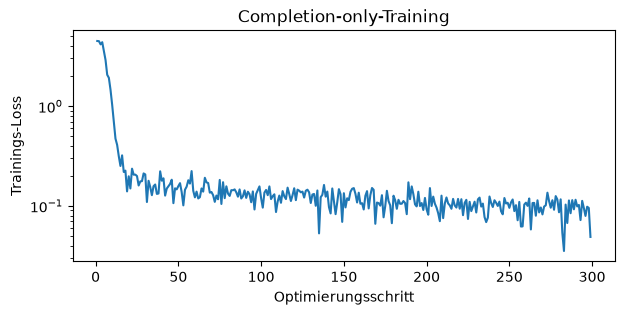

In [9]:
import matplotlib.pyplot as plt

RUN_DIR = "docs/training/runs/train-e6c6c4dd8f6caaf9"
losses = [
    row for row in support.load_jsonl(f"{RUN_DIR}/loss.jsonl") if "loss" in row
]

figure, axis = plt.subplots(figsize=(7, 3))
axis.plot([row["step"] for row in losses], [row["loss"] for row in losses])
axis.set_xlabel("Optimierungsschritt")
axis.set_ylabel("Trainings-Loss")
axis.set_yscale("log")
axis.set_title("Completion-only-Training")
plt.show()

## 5 Evaluation

- Metrik **TaskSuccess**: der Plan läuft fehlerfrei in PyMOL *und* erzeugt exakt den erwarteten Zustand
- zwei Bedingungen:
    - `no-grammar`: freie Generierung
    - `grammar`: die Engine erzwingt per **Grammatik**, dass nur die eingeschränkte Sprache entsteht
- Vergleich Basismodell gegen Fine-Tune, gepaart je Beispiel, mit exaktem zweiseitigem **McNemar-Test**
- Vergleich und Endpunkt wurden festgelegt, *bevor* eines der Modelle ausgewertet war

In [10]:
from pmc_eval.compare import compare
from pmc_eval.eval_cli import read_run

EVALUATION = support.ROOT / "docs" / "evaluation"
CONFIGS = support.ROOT / "configs" / "evaluation"

# compare() rechnet jeden Bericht aus den gespeicherten Einzelergebnissen nach
vergleich = compare(
    EVALUATION / "baseline",
    EVALUATION / "finetuned",
    CONFIGS / "baseline.json",
    CONFIGS / "finetuned.json",
    read_run,
)
zeilen = []
for menge in ("test_gold", "heldout_synthetic"):
    for bedingung in ("no-grammar", "grammar"):
        block = vergleich["sets"][menge][bedingung]
        paar = block["paired_task_success"]
        tuned = block["overall"]["**TaskSuccess**"]["candidate"]
        zeilen.append(
            (
                menge,
                bedingung,
                support.rate(0, paar["n"]),
                support.rate(tuned["k"], tuned["n"]),
                f"{paar['mcnemar_exact_p']:.2g}",
            )
        )
support.markdown_table(
    ["Testmenge", "Bedingung", "Basismodell", "Fine-Tune", "McNemar p"], zeilen
)

| Testmenge | Bedingung | Basismodell | Fine-Tune | McNemar p |
| --- | --- | --- | --- | --- |
| test_gold | no-grammar | 0/68 (0.0%) | 19/68 (27.9%) | 3.8e-06 |
| test_gold | grammar | 0/68 (0.0%) | 32/68 (47.1%) | 4.7e-10 |
| heldout_synthetic | no-grammar | 0/842 (0.0%) | 842/842 (100.0%) | 6.8e-254 |
| heldout_synthetic | grammar | 0/842 (0.0%) | 842/842 (100.0%) | 6.8e-254 |

- Basismodell: **nie** erfolgreich
    - ohne Grammatik kopiert es die Strukturkarte zurück
    - mit Grammatik wiederholt es Befehle bis zum Token-Limit
- Fine-Tune: unter **beiden** Bedingungen klar besser als das Basismodell
    - mit Grammatik fast die Hälfte der Gold-Wünsche richtig
- `heldout_synthetic` vollständig richtig, aber: gleiche Satzvorlagen wie im Training (Abschnitt 3.4)
- Was noch scheitert, sind **Umformulierungen** (Paraphrasen):
    - ohne Grammatik behält das Modell oft das Verb der Nutzer:in ("make the zinc ions magenta" wird zu `make magenta, ...`)
    - aus Alltagsnamen werden erfundene Atomnamen ("the alpha carbons" wird zu `name ALPH`)
    - "chains A and B" wird als `and` gelesen, gemeint ist aber `or`

## 6 Anwendung: der Copilot in PyMOL

- ein lokaler Server lädt den Fine-Tune über **Lemonade** (lokaler Inferenzserver, CPU oder GPU)
- in PyMOL registriert der Client neue Befehle:
    - `copilot <Wunsch>`: Plan erzeugen und als Vorschau zeigen
    - `copilot_apply <id>`: Plan anwenden
    - `copilot_reject <id>`: Plan verwerfen
    - `copilot_rollback <id>`: angewendeten Plan komplett rückgängig machen

### 6.1 Server und PyMOL starten
- Einstellungen des Servers:
    - Name des Modells
    - Kontext von 16.384 Tokens (die Strukturkarte listet jedes Atom)
    - der Prompt aus dem Training und die Grammatik
- die Engine hängt vom Rechner ab:
    - Entwicklungsrechner: Lemonade in Docker
    - Windows-Bundle: eigenes Lemonade auf der CPU, prüft vorher die SHA-256 des Modells

In [11]:
MODEL_NAME = "Llama-3.2-1B-Instruct-pmc-train-e6c6c4dd8f6caaf9-Q4_K_M"
CONTEXT_SIZE = 16384
SERVER_FLAGS = [
    "--model-name",
    MODEL_NAME,
    "--context-size",
    str(CONTEXT_SIZE),
    "--read-timeout-seconds",
    "600",
    "--prompt",
    "training",
    "--grammar",
    "--max-tokens",
    "256",
    "--generation-deadline-seconds",
    "600",
]
print("python -m pmc_server.main", " ".join(SERVER_FLAGS), "<Engine-Flags>")

python -m pmc_server.main --model-name Llama-3.2-1B-Instruct-pmc-train-e6c6c4dd8f6caaf9-Q4_K_M --context-size 16384 --read-timeout-seconds 600 --prompt training --grammar --max-tokens 256 --generation-deadline-seconds 600 <Engine-Flags>


- PyMOL läuft ohne Fenster (headless) in diesem Kernel
- geladen wird die Struktur aus Abschnitt 3.1: `two_chains_hetatm`, im Training **nie** gesehen
    - zwei Ketten, ein Zink-Ion und ein Wasser
- dann verbindet sich der Client mit dem Server

In [12]:
import tempfile

from pmc_client.bootstrap import connect_from_handoff
from pmc_client.recovery import RecoveryStore
from pmc_core.snapshot import reconstruct

ausgabe: list[str] = []
if RUN_DEMO:
    # Engine und Server starten; der Server schreibt Port und Schlüssel in handoff
    lemonade = support.start_engine(MODEL_NAME, CONTEXT_SIZE)
    print("Engine:", " ".join(lemonade.flags))
    arbeitsordner = Path(tempfile.mkdtemp(prefix="pmc-notebook-"))
    handoff = arbeitsordner / "session.json"
    server = support.start_server([*SERVER_FLAGS, *lemonade.flags], handoff)

    # PyMOL mit der Struktur füllen und den Client verbinden
    cmd = support.launch_pymol()
    reconstruct(cmd, snapshot)
    driver = support.ConsoleDriver(cmd)
    client = connect_from_handoff(
        driver,
        ausgabe.append,
        path=handoff,
        recovery_store=RecoveryStore(arbeitsordner),
    )
    print("\n".join(ausgabe))
    ausgabe.clear()
else:
    print("RUN_DEMO ist aus: PMC_NOTEBOOK_DEMO=1 setzen, mit Lemonade-Server.")

Engine: --checkpoint /models/train-e6c6c4dd8f6caaf9/export/Llama-3.2-1B-Instruct-pmc-train-e6c6c4dd8f6caaf9-Q4_K_M.gguf --backend cpu


cmd.sync() timed out (lock_attempt)


cmd.sync() timed out (lock_attempt)
copilot: connected to the server on 127.0.0.1:33469.


### 6.2 Ein Wunsch in eigenen Worten
- der Wunsch aus Abschnitt 3.1 (Gold-Wunsch `gold_056`)
- Dauer einer Antwort:
    - GPU: wenige Sekunden
    - CPU: zehn Sekunden bis etwa eine Minute, fast alles fürs Lesen des Prompts (der Strukturkarte)

In [13]:
WUNSCH = "select the zinc ions, make them silver and show them as dots"
if RUN_DEMO:
    farbe_vorher = []
    cmd.iterate("resn ZN", "farbe_vorher.append(color)", space=locals())
    sekunden = driver.run(f"copilot {WUNSCH}")
    vorschau = "\n".join(ausgabe)
    ausgabe.clear()
    print(vorschau)
    print(f"\n(beantwortet in {sekunden:.1f} s)")

PyMOL>copilot select the zinc ions, make them silver and show them as dots


copilot plan p-74950171-da95-4fcf-b997-06fc8c94a1fc (expires 2026-10-25T13:33:48.839Z, in 5 min)
  object:    pmc_structure (36 atoms, 1 state)
  commands:
    1 | select copilot_sel0249, name ZN   -> 2 atoms
    2 | color silver, copilot_sel0249
    3 | show dots, copilot_sel0249
  warnings:  none
  fidelity:  exact on the declared state scope
  checked:   the plan parses, policy allows it, and a fresh PyMOL sidecar reconstructed this session's declared state exactly, then ran the plan against it -- the counts above are from that run
  NOT checked: whether this is scientifically what you meant
  apply:     copilot_apply p-74950171-da95-4fcf-b997-06fc8c94a1fc
  reject:    copilot_reject p-74950171-da95-4fcf-b997-06fc8c94a1fc

(beantwortet in 9.4 s)


- die Vorschau zeigt:
    - die Befehle
    - wie viele Atome jede Selektion beim Probelauf in einem separaten PyMOL-Prozess getroffen hat
    - was geprüft wurde und was **nicht** (ob der Plan fachlich gemeint war)
- die Sitzung ist bis hierhin **unverändert**
- Beachte: in der Evaluation wählte das Modell `name ZN` statt `resn ZN`
    - auf dieser Struktur treffen beide dieselben zwei Atome, daher als richtig gewertet
- Zeilen wie `cmd.sync() timed out` sind Meldungen von PyMOL im Notebook-Kernel; die Befehle laufen trotzdem vollständig

### 6.3 Plan anwenden
- `copilot_apply` sichert zuerst die Sitzung, dann laufen die Befehle

In [14]:
plan_id = None
if RUN_DEMO:
    plan_id = support.plan_id(vorschau)
if plan_id is not None:
    driver.run(f"copilot_apply {plan_id}")
    print("\n".join(ausgabe))
    ausgabe.clear()
    farbe_nachher = []
    cmd.iterate("resn ZN", "farbe_nachher.append(color)", space=locals())
    print("Farbindex Zink vorher:", farbe_vorher, "nachher:", farbe_nachher)
    print("Angelegte Selektion:", cmd.get_names("selections"))
elif RUN_DEMO:
    print("Der Copilot hat keinen Plan angeboten; siehe seine Antwort oben.")

PyMOL>copilot_apply p-74950171-da95-4fcf-b997-06fc8c94a1fc


cmd.sync() timed out (wait_queue)


cmd.sync() timed out (wait_queue)


cmd.sync() timed out (wait_queue)
copilot_apply: plan p-74950171-da95-4fcf-b997-06fc8c94a1fc applied. Recovery point retained at /tmp/pmc-notebook-7c5qg_wa/.pymol-copilot/recovery/plan-74950171-da95-4fcf-b997-06fc8c94a1fc.pse.
Farbindex Zink vorher: [6, 6] nachher: [5322, 5322]
Angelegte Selektion: ['copilot_sel0249']


### 6.4 Ein Wunsch, der nie ausgewertet wurde

In [15]:
if RUN_DEMO:
    driver.run("copilot colour chain B marine and show it as sticks")
    print("\n".join(ausgabe))
    ausgabe.clear()

PyMOL>copilot colour chain B marine and show it as sticks


copilot plan p-534cb19e-6618-4480-92c1-ac4c2684aeec (expires 2026-10-25T13:33:58.772Z, in 5 min)
  object:    pmc_structure (36 atoms, 1 state)
  commands:
    1 | color marine, chain B
    2 | show sticks, chain B
  warnings:  none
  fidelity:  exact on the declared state scope
  checked:   the plan parses, policy allows it, and a fresh PyMOL sidecar reconstructed this session's declared state exactly, then ran the plan against it -- the counts above are from that run
  NOT checked: whether this is scientifically what you meant
  apply:     copilot_apply p-534cb19e-6618-4480-92c1-ac4c2684aeec
  reject:    copilot_reject p-534cb19e-6618-4480-92c1-ac4c2684aeec


### 6.5 Rückgängig machen
- ein unerwünschter Plan wird einfach nicht angewendet: `copilot_reject` verwirft ihn
- ein angewendeter Plan lässt sich als Ganzes zurücknehmen, da die Sitzung vorher gesichert wurde:

In [16]:
if plan_id is not None:
    driver.run(f"copilot_rollback {plan_id}")
    print("\n".join(ausgabe))
    ausgabe.clear()
    farbe_zurueck = []
    cmd.iterate("resn ZN", "farbe_zurueck.append(color)", space=locals())
    print("Farbindex Zink nach dem Rollback:", farbe_zurueck)
if RUN_DEMO:
    support.stop_server(server)
    support.stop_engine(lemonade)

PyMOL>copilot_rollback p-74950171-da95-4fcf-b997-06fc8c94a1fc
copilot_rollback: replacing the entire session with the pre-apply recovery point; later changes will be discarded.
copilot_rollback: plan p-74950171-da95-4fcf-b997-06fc8c94a1fc rolled back and its recovery point was removed.
Farbindex Zink nach dem Rollback: [6, 6]


## 7 Grenzen und Ausblick

- nur **ein** Trainingslauf mit **einem** Seed, keine Ablationen
- nur die Quantisierung Q4_K_M ausgewertet
- Strukturen sind synthetisch und enthalten nur Rückgrat-Atome
- der Term `polymer` wird nie bewertet, `orient` nur über die Anzahl getroffener Atome
- integrierte GPUs (Vulkan) sind unerprobt; gemessen wurden CPU und eine NVIDIA-GPU
- Wünsche im Training stammen aus **Satzvorlagen**
    - größte Schwäche: **natürliche Formulierungen**
    - hier muss der nächste Datensatz wachsen

### Übung
- Wählen Sie aus `kandidaten` (Abschnitt 3.2) einen Plan, der das Verb `hide` verwendet
- Lassen Sie ihn vom Orakel (`apply_plan`) bewerten: wie viele Atome trifft jede Selektion?
- Prüfen Sie mit `parse_pml`, ob der Parser den gerenderten Plan (`render_pml()`) akzeptiert